# Healthcare appointment operations

Synthetic 2025 portfolio case study. Run from the project root or the python folder. This notebook inspects the checked-in inputs; run `python python/run_all.py` to rebuild every saved output.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'python'))
from metrics import prepare,summarize
frame,departments=prepare()
print('Input records:',len(frame))
print(frame.head().to_string(index=False))


Input records: 3600
appointment_id patient_id appointment_date booking_date department_id  clinic visit_type   status  reminder_sent  wait_minutes  service_minutes       department  wait_target_minutes  lead_days lead_band
        A00001      P0301       2025-03-06   2025-02-21           D01   North        New Attended              1          50.0             27.0 General Medicine                   30         13 8-21 days
        A00002      P0148       2025-07-24   2025-05-30           D01 Central        New  No-show              1           NaN              NaN General Medicine                   30         55  22+ days
        A00003      P0746       2025-12-04   2025-10-23           D01   South  Follow-up Attended              1          19.0             19.0 General Medicine                   30         42  22+ days
        A00004      P0441       2025-10-27   2025-10-23           D04 Central        New Attended              1          13.0             23.0      Orthopedics        

## Metric definitions
No-show rate excludes cancelled bookings. Wait measures use attended visits only; missing wait values on other outcomes are expected, while zero wait is valid. The 30-minute threshold is a simulation assumption, not a clinical standard.

In [2]:
summary=summarize(frame)
print(pd.Series(summary).to_string())


bookings              3600.000000
attended              2765.000000
no_shows               485.000000
cancelled              350.000000
no_show_rate             0.149231
avg_wait_minutes        30.443038
within_target_rate       0.499458


## Segment comparison
Compare groups descriptively; the generator deliberately introduces patterns, so results are not causal evidence.

In [3]:
rows=[]
for name,group in frame.groupby('department'):
    rows.append({'department':name,**summarize(group)})
comparison=pd.DataFrame(rows)
print(comparison.to_string(index=False))


      department  bookings  attended  no_shows  cancelled  no_show_rate  avg_wait_minutes  within_target_rate
      Cardiology       604       481        75         48      0.134892         39.349272            0.237006
     Dermatology       442       337        56         49      0.142494         20.795252            0.792285
General Medicine      1068       827       136        105      0.141225         28.493349            0.562273
   Ophthalmology       378       307        41         30      0.117816         24.908795            0.674267
     Orthopedics       555       405        98         52      0.194831         35.785185            0.313580
      Pediatrics       553       408        79         66      0.162218         30.725490            0.492647


## Visual exploration

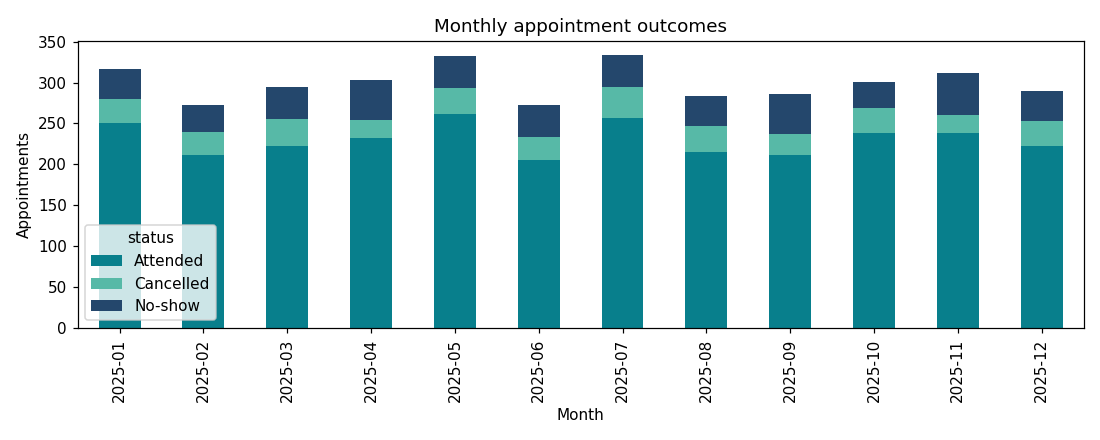

In [4]:
monthly=frame.assign(month=frame.appointment_date.dt.to_period('M').astype(str)).groupby(['month','status']).size().unstack(fill_value=0)
monthly.plot(kind='bar',stacked=True,figsize=(10,4),color=['#087f8c','#57b9a7','#24476c'],title='Monthly appointment outcomes')
plt.ylabel('Appointments');plt.xlabel('Month');plt.tight_layout();plt.show()


## Findings and next steps
Compare lead-time bands, inspect department queues and design a reminder pilot before claiming an operational improvement. See the Word handbook for numerical findings and limitations.